# Exploring specificity prediction normalisation

In this notebook, we explore whether our developped model can normalise the effects that come from more confident structure prediction.

In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import umap
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from sklearn.metrics import roc_auc_score

from tcr_pmhc_predicted_structures.models import PAEAggregator

2026-02-10 11:06:58.575886: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500_af_training.csv', index_col='id')

In [3]:
confidence_scores_1500 = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
confidence_scores_1500['name'] = confidence_scores_1500['name'].astype(str)

confidence_scores_af_training = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_af_training.csv')

confidence_scores = pd.concat([confidence_scores_1500, confidence_scores_af_training]).reset_index(drop=True)

In [4]:
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

In [5]:
confidence_scores['type'] = confidence_scores['label'].map(lambda label: 'Binder' if label else 'Non-Binder')

In [6]:
min_size = confidence_scores.value_counts(['source', 'label']).min()
confidence_scores_down_sample = confidence_scores.groupby(['source', 'label']).sample(min_size, random_state=123)

In [7]:
def plot_separation(
    data: pd.DataFrame, x: str, *, invert_roc_auc: bool = False, clip: tuple[float, float] | None = None
) -> tuple[Figure, Axes]:
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    for i, (data_subset, title, separator, hue, invert_score) in enumerate(
        zip(
            (data[data['source'] == 'Sequences'], data[data['source'] == 'AF Training'], data, data),
            ('Sequences', 'AF training structures', 'Overall', 'Using data source'),
            ('label', 'label', 'label', 'source'),
            ('type', 'type', 'type', 'source'),
            (True, True, True, False),
            strict=True,
        )
    ):
        axes[i % 2, i // 2].set_title(title)
        ax = sns.kdeplot(
            data_subset,
            x=x,
            hue=hue,
            ax=axes[i % 2, i // 2],
            fill=True,
            clip=clip,
        )

        legend = ax.get_legend()
        legend.set_title(legend.get_title().get_text().title())

        score = roc_auc_score(data_subset[separator], data_subset[x])
        if invert_score ^ invert_roc_auc:
            score = 1 - score

        axes[i % 2, i // 2].text(
            0.50,
            0.95,
            f'ROC-AUC: {score: .2f}',
            transform=axes[i % 2, i // 2].transAxes,
            fontsize=12,
            horizontalalignment='center',
            verticalalignment='top',
        )

    return fig, axes

## Original

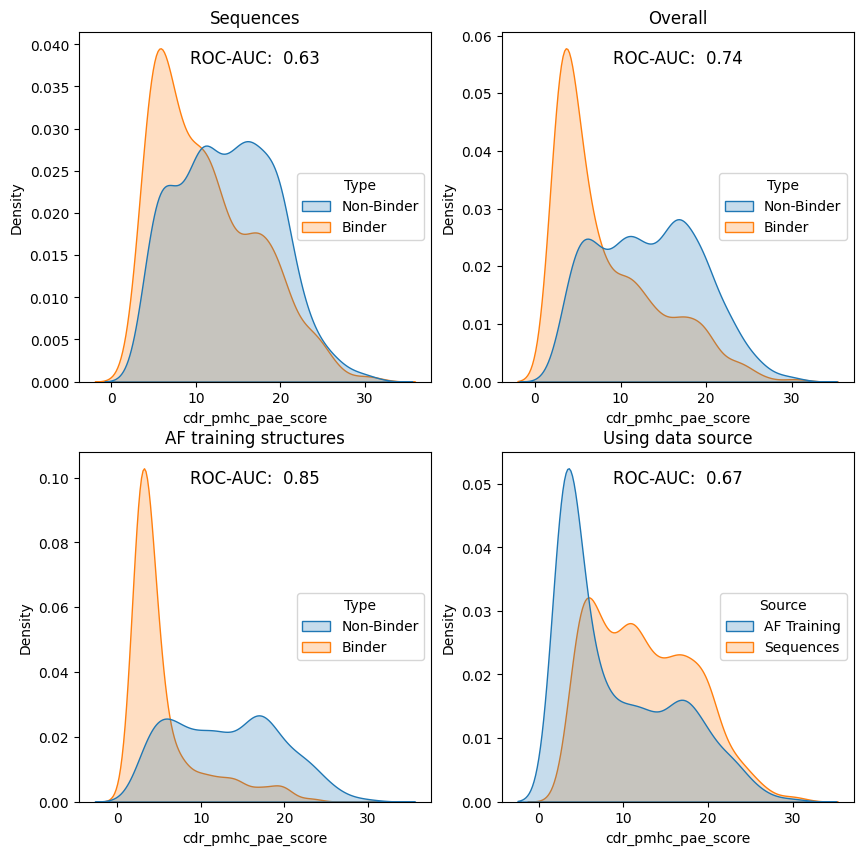

In [8]:
plot_separation(confidence_scores_down_sample, x='cdr_pmhc_pae_score')
plt.show()

Here, we see an effect that the distribution that the pairing comes from can have a larger effect than the label of that pairing.

## Model

In [9]:
with h5py.File('../data/processed/af3_af3_tcrmodel2_pae.h5', 'r') as fh:
    paes = fh['pae'][:]

    names = np.array([name.decode() for name in fh['id'][:]])
    seeds = fh['seed'][:]
    samples = fh['sample'][:]

    folds = fh['fold'][:]

### Untrained

In [10]:
model = PAEAggregator(3120)
model.eval()

predictions = model(torch.Tensor(paes)).cpu().detach().numpy()
latents = torch.mul(model.weights, torch.Tensor(paes)).cpu().detach().numpy()

untrained_predictions = pd.DataFrame(
    {
        'name': names,
        'seed': seeds,
        'sample': samples,
        'untrained_prediction': predictions,
        'untrained_latents': list(latents),
    }
)

In [11]:
confidence_scores_down_sample = confidence_scores_down_sample.merge(
    untrained_predictions, how='left', on=['name', 'seed', 'sample']
)

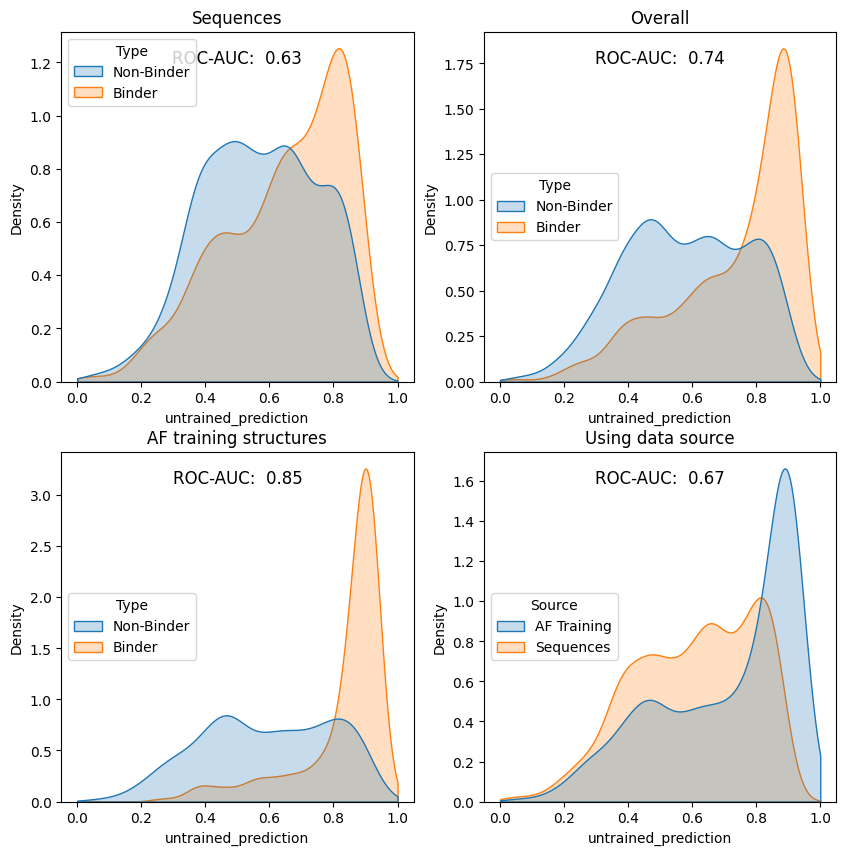

In [12]:
plot_separation(confidence_scores_down_sample, x='untrained_prediction', invert_roc_auc=True, clip=(0, 1))
plt.show()

In [13]:
untrained_umap = umap.UMAP(random_state=123).fit_transform(
    np.vstack(confidence_scores_down_sample['untrained_latents'])
)

/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


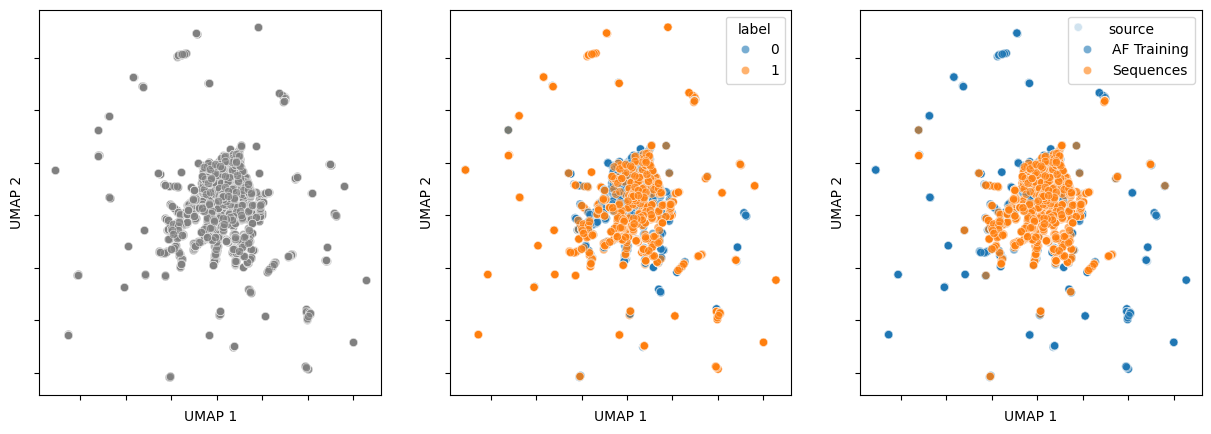

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.scatterplot(x=untrained_umap[:, 0], y=untrained_umap[:, 1], alpha=0.6, color='grey', ax=axes[0])
sns.scatterplot(
    x=untrained_umap[:, 0], y=untrained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['label'], ax=axes[1]
)
sns.scatterplot(
    x=untrained_umap[:, 0], y=untrained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['source'], ax=axes[2]
)

for ax in axes:
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

plt.show()

### Trained

In [15]:
trained_predictions = pd.DataFrame()

for fold in sorted(np.unique(folds)):
    model = PAEAggregator(3120)
    model.load_state_dict(
        torch.load(
            f'../models/PAEAggregator_af3_af3_tcrmodel2/model_{fold}.pt',
            weights_only=True,
            map_location=torch.device('cpu'),
        ),
    )
    model.eval()

    fold_mask = folds == fold

    predictions = model(torch.Tensor(paes[fold_mask])).cpu().detach().numpy()
    latents = torch.mul(model.weights, torch.Tensor(paes[fold_mask])).cpu().detach().numpy()

    trained_predictions = pd.concat(
        [
            trained_predictions,
            pd.DataFrame(
                {
                    'name': names[fold_mask],
                    'seed': seeds[fold_mask],
                    'sample': samples[fold_mask],
                    'trained_prediction': predictions,
                    'trained_latents': list(latents),
                }
            ),
        ]
    )

In [16]:
confidence_scores_down_sample = confidence_scores_down_sample.merge(
    trained_predictions, how='left', on=['name', 'seed', 'sample']
)

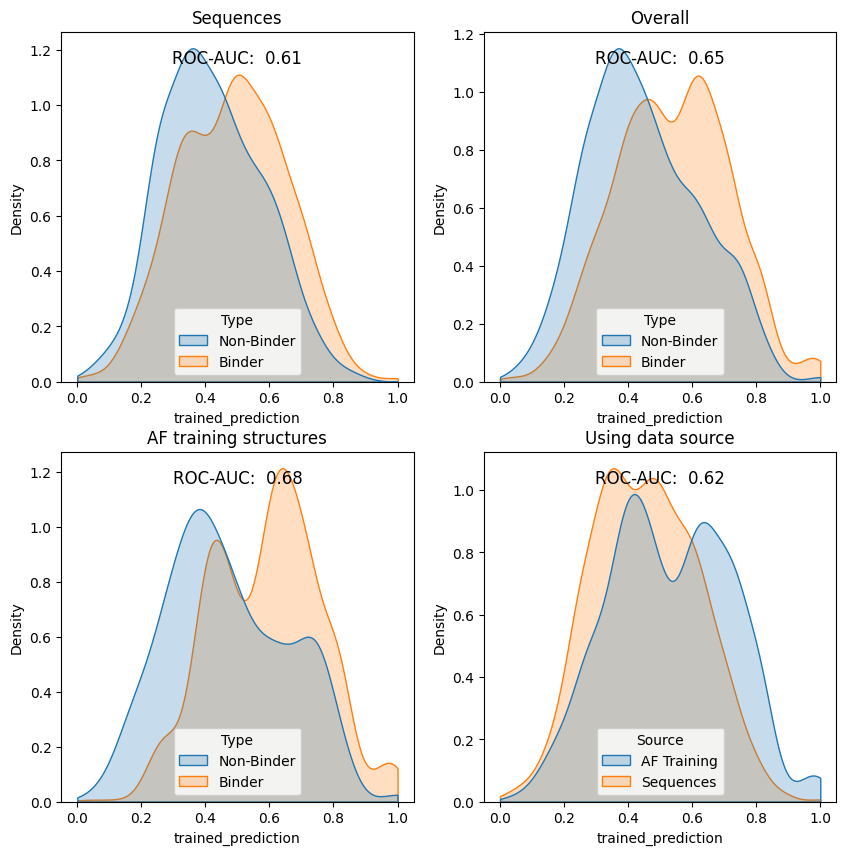

In [17]:
plot_separation(confidence_scores_down_sample, x='trained_prediction', invert_roc_auc=True, clip=(0, 1))
plt.show()

In [18]:
trained_umap = umap.UMAP(random_state=123).fit_transform(np.vstack(confidence_scores_down_sample['trained_latents']))

/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


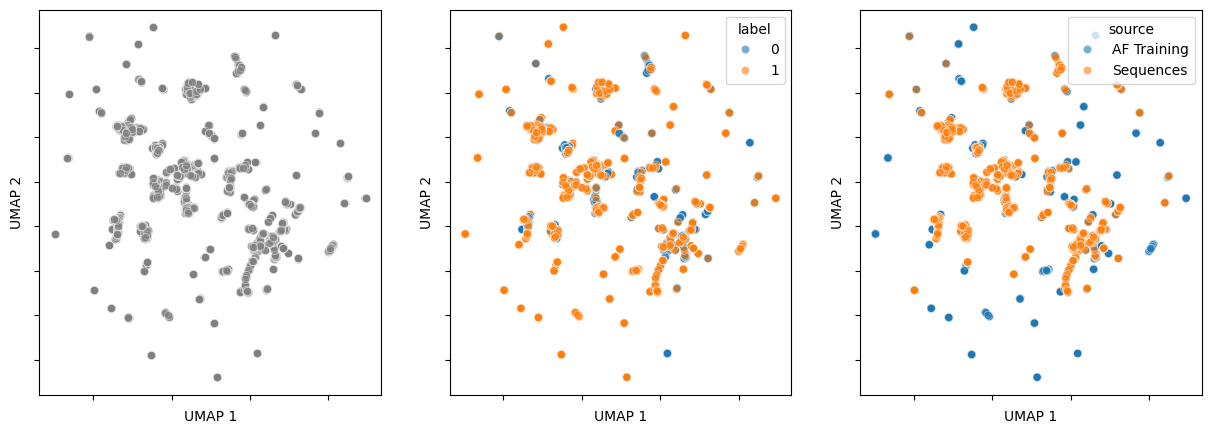

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.scatterplot(x=trained_umap[:, 0], y=trained_umap[:, 1], alpha=0.6, color='grey', ax=axes[0])
sns.scatterplot(
    x=trained_umap[:, 0], y=trained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['label'], ax=axes[1]
)
sns.scatterplot(
    x=trained_umap[:, 0], y=trained_umap[:, 1], alpha=0.6, hue=confidence_scores_down_sample['source'], ax=axes[2]
)

for ax in axes:
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

plt.show()

## Combined Results

In [20]:
confidence_scores_down_sample_sequences = confidence_scores_down_sample[
    confidence_scores_down_sample['source'] == 'Sequences'
]

roc_auc_scores = {
    'prediction_status': [],
    'antigen_specificity': [],
    'data_source': [],
}
for prediction_status in ('untrained_prediction', 'trained_prediction'):
    roc_auc_scores['prediction_status'].append(prediction_status)

    roc_auc_scores['antigen_specificity'].append(
        roc_auc_score(
            confidence_scores_down_sample_sequences['label'], confidence_scores_down_sample_sequences[prediction_status]
        )
    )

    roc_auc_scores['data_source'].append(
        1 - roc_auc_score(confidence_scores_down_sample['source'], confidence_scores_down_sample[prediction_status])
    )

roc_auc_scores = pd.DataFrame(roc_auc_scores)

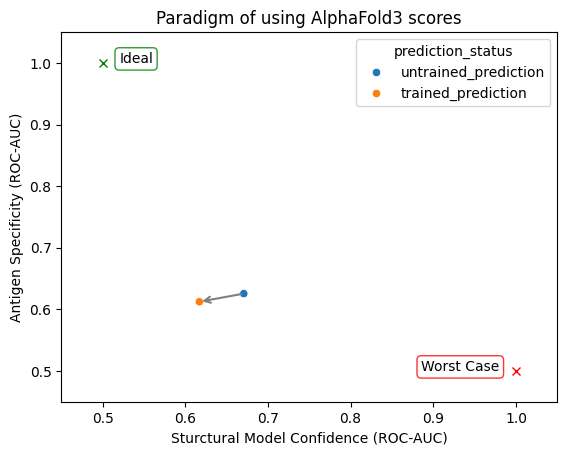

In [21]:
ax = sns.scatterplot(roc_auc_scores, x='data_source', y='antigen_specificity', hue='prediction_status')

ax.annotate(
    '',
    xy=roc_auc_scores[roc_auc_scores['prediction_status'] == 'trained_prediction']
    .iloc[0][['data_source', 'antigen_specificity']]
    .tolist(),
    xytext=roc_auc_scores[roc_auc_scores['prediction_status'] == 'untrained_prediction']
    .iloc[0][['data_source', 'antigen_specificity']]
    .tolist(),
    arrowprops={'arrowstyle': '->', 'color': 'gray', 'lw': 1.5},
    fontsize=11,
    ha='center',
)

ax.plot([0.5], [1.0], marker='x', color='green')
ax.text(
    0.52, 1.0, 'Ideal', bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'edgecolor': 'green', 'alpha': 0.8}
)

ax.plot([1.0], [0.5], marker='x', color='red')
ax.text(
    0.98,
    0.5,
    'Worst Case',
    ha='right',
    bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'edgecolor': 'red', 'alpha': 0.8},
)

ax.set_xlim(0.45, 1.05)
ax.set_ylim(0.45, 1.05)

ax.set_ylabel('Antigen Specificity (ROC-AUC)')
ax.set_xlabel('Sturctural Model Confidence (ROC-AUC)')
ax.set_title('Paradigm of using AlphaFold3 scores')

plt.show()